# 가우시안 분포 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week03/gaussian/lab/gaussian.ipynb)

작은 효과의 합이 종 모양을 만든다. 골턴 보드를 시뮬레이션하고, 실제 펭귄 데이터에 종을 맞추고, 종 두 개로 분류해 본다.

- **파트 1**: 골턴 보드 시뮬레이션
- **파트 2**: 펭귄 날개 길이에 가우시안 맞추기 ($\hat\mu$, $\hat\sigma$, 68% 규칙)
- **파트 3**: 가우시안 + 베이즈 정리로 펭귄 종 맞히기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from math import comb

## 파트 1. 골턴 보드

공은 못 10줄을 지나며 매번 오른쪽(1) 또는 왼쪽(0) 으로 반반 튄다. 공이 떨어지는 칸 = 오른쪽으로 튄 횟수.
슬라이드: 공 1000개면 가운데 칸에 약 246개.

In [ ]:
def galton(n_balls, n_rows, seed=0):
    rng = np.random.default_rng(seed)
    bounces = rng.integers(0, 2, size=(n_balls, n_rows))  # 1 = bounced right
    return None  # TODO: bin of each ball = number of right bounces

bins = galton(1000, 10)
counts = np.bincount(bins, minlength=11)
expected = [round(1000 * comb(10, k) / 2 ** 10) for k in range(11)]
print("simulated:", counts.tolist())
print("expected :", expected)
plt.bar(range(11), counts); plt.xlabel("bin (right bounces)"); plt.ylabel("balls"); plt.show()

**예상 결과**

```
simulated: [4, 6, 42, 112, 207, 236, 227, 109, 45, 9, 3]
expected : [1, 10, 44, 117, 205, 246, 205, 117, 44, 10, 1]
```

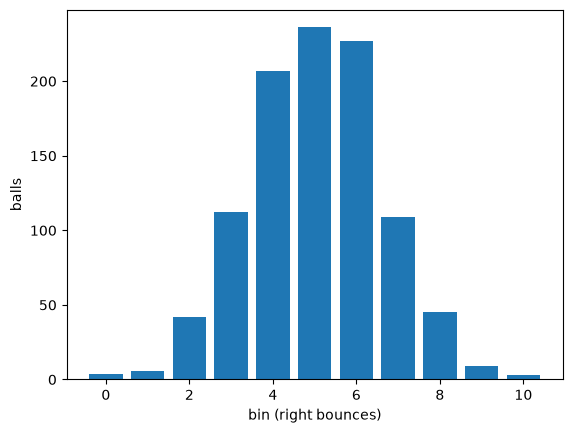

In [ ]:
# More rows -> smoother bell
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, rows in zip(axs, [3, 10, 50]):
    b = galton(20000, rows)
    ax.hist(b, bins=np.arange(rows + 2) - 0.5); ax.set_title(f"{rows} rows")
plt.show()

**예상 결과**

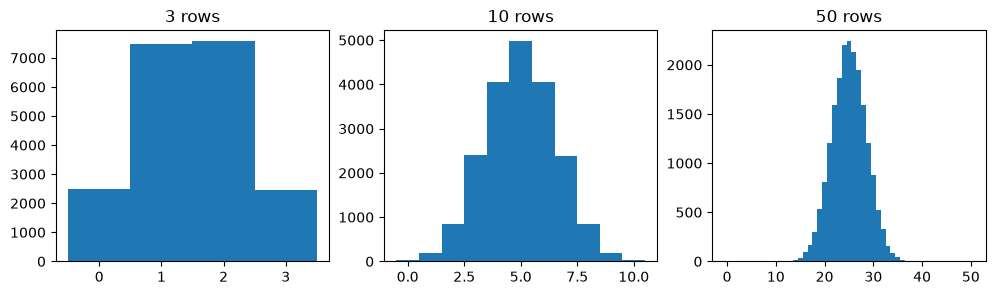

## 파트 2. 실제 데이터에 종 맞추기

남극 펭귄 3종(Adelie, Chinstrap, Gentoo) 333마리의 날개 길이(mm). 처음 실행하면 CSV 를 내려받는다.

$$\hat\mu = \frac{1}{m}\sum x^{(i)}, \qquad \hat\sigma^2 = \frac{1}{m}\sum \big(x^{(i)} - \hat\mu\big)^2$$

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/penguins.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/penguins.csv")
df = pd.read_csv("data/penguins.csv").dropna()
print(df["species"].value_counts())
df.head()

**예상 결과**

```
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
4       3450.0  FEMALE  
5       3650.0    MALE  
```

In [ ]:
def fit_gaussian(x):
    mu = np.mean(x)
    sigma = None  # TODO: MLE standard deviation (divide by m)
    return mu, sigma

def gaussian_pdf(x, mu, sigma):
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma)

xs = np.linspace(165, 235, 300)
params = {}
for sp in ["Adelie", "Chinstrap", "Gentoo"]:
    x = df.loc[df["species"] == sp, "flipper_length_mm"].to_numpy(float)
    mu, sigma = fit_gaussian(x)
    params[sp] = (mu, sigma)
    inside = None  # TODO: fraction within mu ± sigma
    print(f"{sp:9s}: n={len(x):3d}  mu={mu:6.1f}  sigma={sigma:4.1f}  within 1 sigma: {inside:.0%}")
    plt.hist(x, bins=20, density=True, alpha=0.35)
    plt.plot(xs, gaussian_pdf(xs, mu, sigma), lw=2, label=sp)
plt.xlabel("flipper length (mm)"); plt.legend(); plt.show()

**예상 결과**

```
Adelie   : n=146  mu= 190.1  sigma= 6.5  within 1 sigma: 71%
Chinstrap: n= 68  mu= 195.8  sigma= 7.1  within 1 sigma: 68%
Gentoo   : n=119  mu= 217.2  sigma= 6.6  within 1 sigma: 61%
```

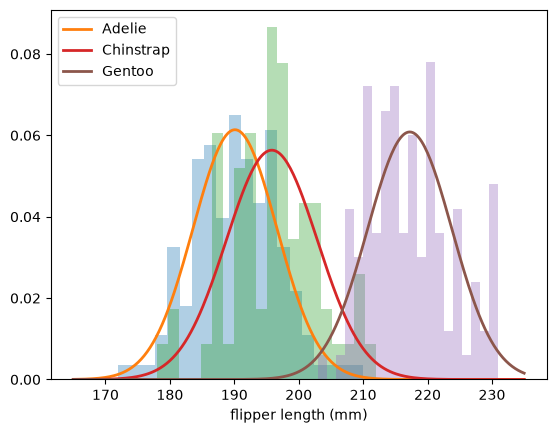

**관찰**: 1σ 안에 든 비율이 68% 에 가까운가?

## 파트 3. 종 두 개로 분류하기

Adelie 와 Chinstrap 은 날개 길이가 겹친다. 날개 길이 하나만 보고 둘을 구별해 보자.

$$P(\text{Adelie} \mid x) = \frac{p(x \mid \text{Adelie})\,P(\text{Adelie})}{p(x \mid \text{Adelie})\,P(\text{Adelie}) + p(x \mid \text{Chinstrap})\,P(\text{Chinstrap})}$$

In [ ]:
two = df[df["species"].isin(["Adelie", "Chinstrap"])]
x = two["flipper_length_mm"].to_numpy(float)
is_adelie = (two["species"] == "Adelie").to_numpy()

def posterior_adelie(x, params, prior_adelie):
    a = gaussian_pdf(x, *params["Adelie"]) * prior_adelie
    c = None  # TODO: Chinstrap likelihood x prior
    return a / (a + c)

prior = is_adelie.mean()
for name, p in [("equal prior 0.5", 0.5), (f"data prior {prior:.2f}", prior)]:
    pred = posterior_adelie(x, params, p) >= 0.5
    print(f"{name:16s}: accuracy {np.mean(pred == is_adelie):.3f}   P(Adelie | 195 mm) = {posterior_adelie(195.0, params, p):.2f}")

**예상 결과**

```
equal prior 0.5 : accuracy 0.687   P(Adelie | 195 mm) = 0.45
data prior 0.68 : accuracy 0.734   P(Adelie | 195 mm) = 0.64
```

In [ ]:
# Compare with scikit-learn's Gaussian naive Bayes (same idea, one feature)
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB().fit(x.reshape(-1, 1), is_adelie)
print("GaussianNB accuracy:", round(nb.score(x.reshape(-1, 1), is_adelie), 3))
print("GaussianNB means:", nb.theta_.ravel().round(1), " stds:", np.sqrt(nb.var_).ravel().round(1))

**예상 결과**

```
GaussianNB accuracy: 0.734
GaussianNB means: [195.8 190.1]  stds: [7.1 6.5]
```

**확인 질문**
1. 파트 1 에서 시뮬레이션 결과가 기대값과 조금 다른 이유는? 공을 10만 개로 늘리면?
2. 파트 2 에서 세 종 중 종 모양에 가장 잘 맞는 것은? 68% 규칙에서 가장 벗어난 종은?
3. 파트 3 에서 사전확률을 반반으로 둘 때와 데이터 비율로 둘 때 정확도가 왜 다른가? 195 mm 펭귄의 판정은 어떻게 바뀌나?
4. (도전) 날개 길이 대신 `bill_length_mm` 를 쓰면 Adelie / Chinstrap 구별이 얼마나 좋아지나?

데이터 출처: Gorman, Williams, Fraser (2014) PLoS ONE 9(3) · Palmer Station LTER, seaborn-data 사본.